# Shluková analýza
* Co je to shluková analýza?

## Cíle cvičení:
* Seznámit se nehierarchickou shlukovací metodou k-means



## Obsah cvičení:
* Implementace metody k-means:
    * Na umělých datech
    * Na reálných datech
* Využití PCA pro extrakci příznaků pro shlukování
* Detekce odlehlých hodnot s využitím shlukování




## Užitečné odkazy
* Understanding K-means: https://towardsdatascience.com/understanding-k-means-clustering-in-machine-learning-6a6e67336aa1
* K-means in Python: https://realpython.com/k-means-clustering-python/


## Importy knihoven a balíčků

In [ ]:
from google.colab import drive
from os import listdir
from os.path import isfile, join
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import scipy.stats as stats
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 50
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("Náhodný seed:", RANDOM_STATE)

Náhodný seed: 50


## Mapování a vytváření dat

In [ ]:
from sklearn.datasets import make_blobs

# Data a jejich skutečné skupiny (štítky) – algoritmus při shlukování štítky nepoužívá.
data_fake = make_blobs(n_samples=200, n_features=2, centers=4,
                       cluster_std=1.6, random_state=RANDOM_STATE)
print("Rozměry dat:", data_fake[0].shape)
print("Skutečné skupiny:", np.unique(data_fake[1], return_counts=True))

Rozměry dat: (200, 2)
Skutečné skupiny: (array([0, 1, 2, 3]), array([50, 50, 50, 50]))


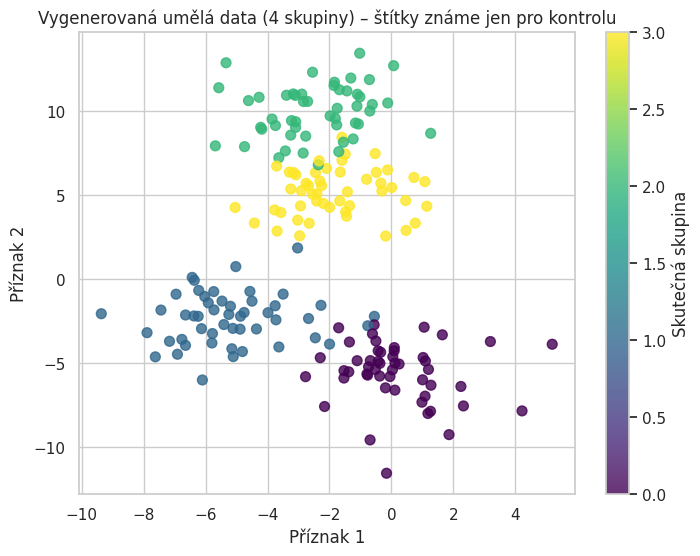

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(data_fake[0][:, 0], data_fake[0][:, 1], c=data_fake[1], cmap="viridis", s=50, alpha=0.8)
plt.title("Vygenerovaná umělá data (4 skupiny) – štítky známe jen pro kontrolu")
plt.xlabel("Příznak 1")
plt.ylabel("Příznak 2")
plt.colorbar(label="Skutečná skupina")
plt.show()

## Implementace k-means shlukování
* Na umělých datech

In [ ]:
# Centroid initialization (by randomly selecting k objects from analyzed dataset)
import random

def init_centroids(data, k_num):
    # Generate random indices to select k initial centroids
    centroids_idx = random.sample(range(len(data)), k_num)

    # Use the selected indices to extract the corresponding data points as centroids
    centroids = data[centroids_idx]

    return np.array(centroids)

centroids = init_centroids(data_fake[0], 4)
print(centroids)


[[-3.42672033  7.64284207]
 [-2.90807981  5.27669491]
 [-1.16095485  9.30443737]
 [-3.72960397 -2.4055241 ]]


In [ ]:
# Calculate squared Euclidian distance between object and centroid
def calc_distance(X1, X2):

    euc_dist = np.sum((X1 - X2) ** 2, axis=1)

    return euc_dist

In [ ]:
# Find the closest centroid for selected object
def find_closest_centroids(centroids, data_array):
    assigned_centroid = []

    for i in range(len(data_array)):
        distance = []
        for j in range(len(centroids)):
            # Compute Euclidean distance between data point and centroid
            dist = calc_distance(data_array[i], centroids[j])

            distance.append(dist)

        # Select the centroid with the minimum distance
        closest_centroid = np.argmin(distance)
        assigned_centroid.append(closest_centroid)

    return assigned_centroid

In [ ]:
# Calculate new centroid positions as mean of object's features
def calc_centroids(cluster_idxs, data_array, centroids):
    new_centroids = []

    for cluster_num in range(len(centroids)):
        current_cluster = data_array[np.array(cluster_idxs) == cluster_num]

        if len(current_cluster) > 0:
            cluster_mean = current_cluster.mean(axis=0)
        else:
            cluster_mean = centroids[cluster_num]

        # Append the new centroid position to the list

        new_centroids.append(cluster_mean)

    return np.array(new_centroids, dtype=float)

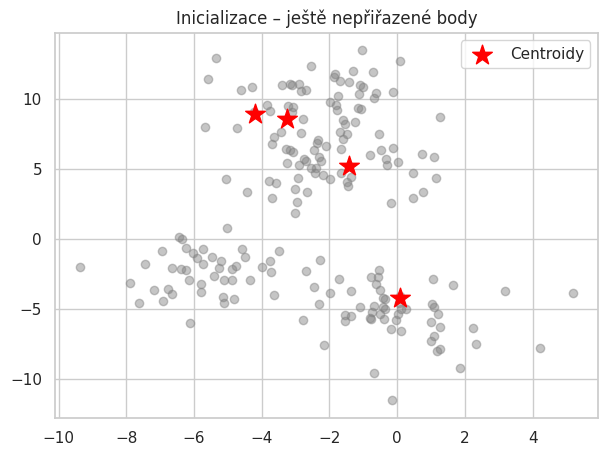

Iterace 1: největší posun centroidu = 2.48716


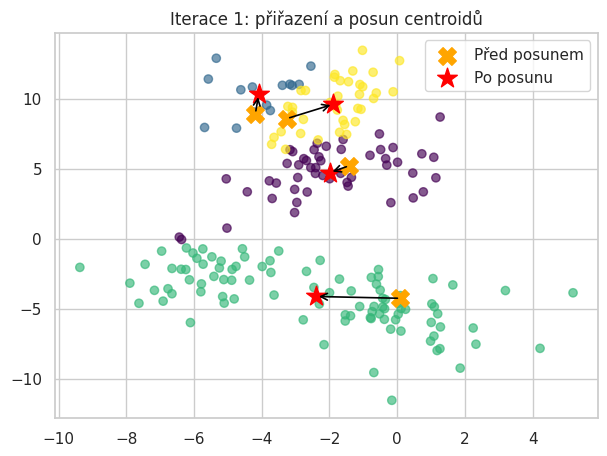

Iterace 2: největší posun centroidu = 0.32905


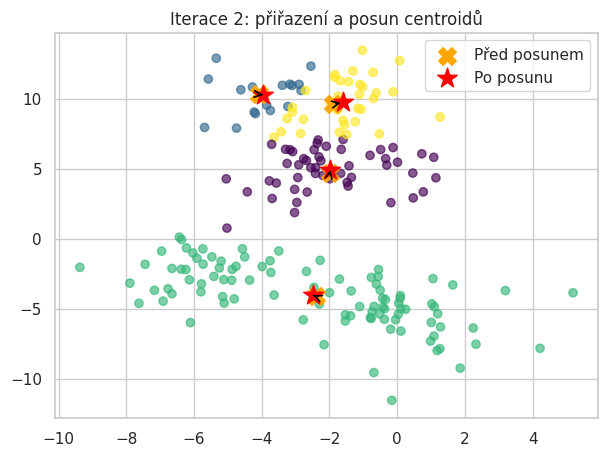

Iterace 3: největší posun centroidu = 0.39160


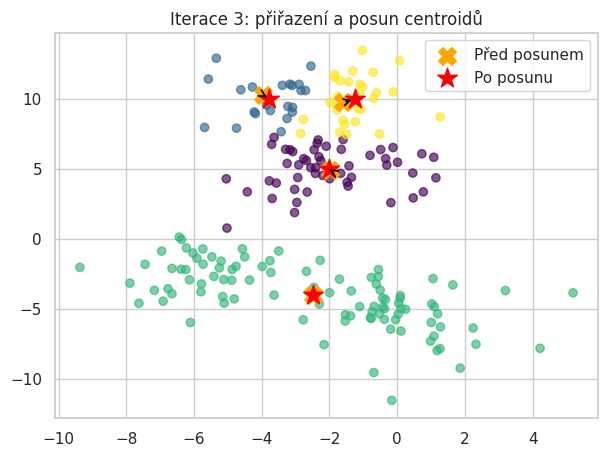

Iterace 4: největší posun centroidu = 0.28050


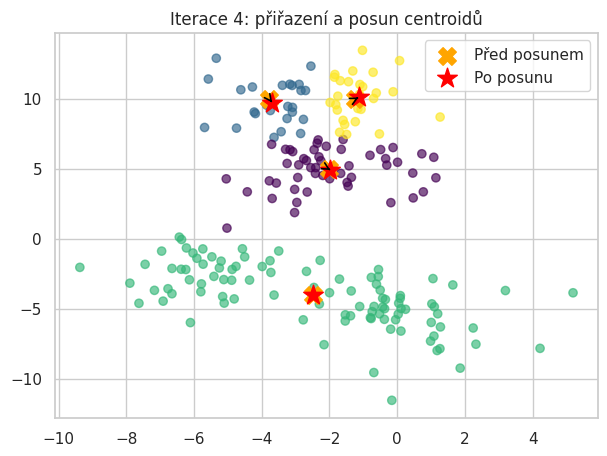

Iterace 5: největší posun centroidu = 0.18480


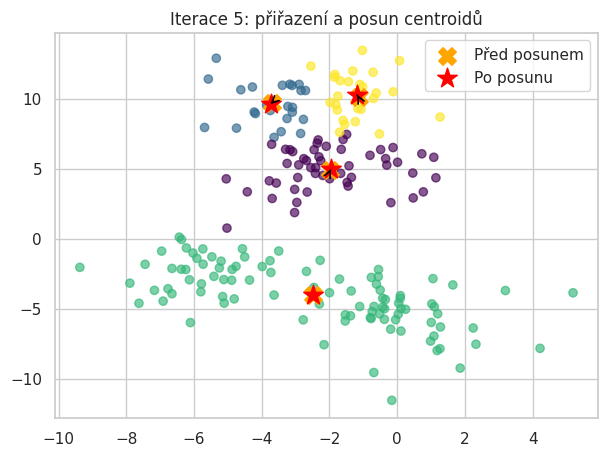

Iterace 6: největší posun centroidu = 0.10446


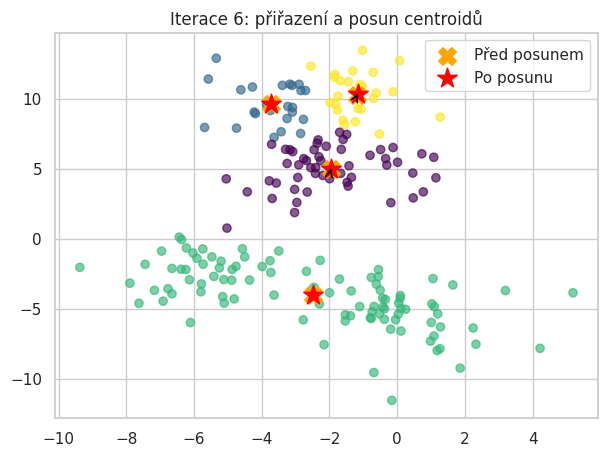

Iterace 7: největší posun centroidu = 0.11815


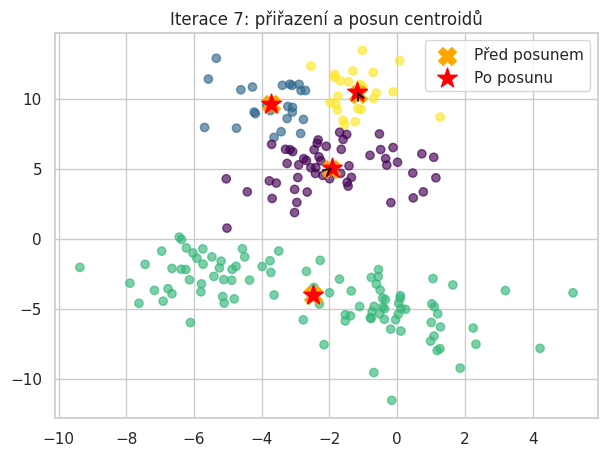

Iterace 8: největší posun centroidu = 0.00000


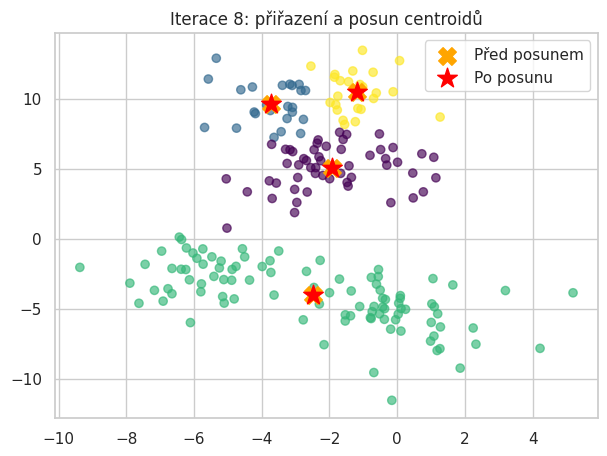

Konvergence: centroidy se už téměř nepohybují.


In [ ]:
# Předefinování pomocné funkce pro výpočet vzdálenosti jednorozměrných bodů, abychom se vyhnuli chybě AxisError
def calc_distance(X1, X2):
    return np.sum((X1 - X2) ** 2)

# Ruční k-means: postupně ukazujeme polohy centroidů, dělení bodů a konvergenci.
def run_kmeans(data_array, k_num, num_of_iter=15,
               show_steps=True, tol=1e-6):
    X = np.asarray(data_array, dtype=float)

    centroids = init_centroids(X, k_num)

    if show_steps:
        plt.figure(figsize=(7, 5))
        plt.scatter(X[:, 0], X[:, 1], alpha=.45, color="gray")
        plt.scatter(centroids[:, 0], centroids[:, 1], color="red", marker="*", s=220, label="Centroidy")
        plt.title("Inicializace – ještě nepřiřazené body")
        plt.legend()
        plt.show()

    for i in range(num_of_iter):
        labels = find_closest_centroids(centroids, X)     # krok 1: přiřazení
        updated = calc_centroids(labels, X, centroids)  # krok 2: přepočet
        shift = np.linalg.norm(updated - centroids, axis=-1).max()
        print(f"Iterace {i+1}: největší posun centroidu = {shift:.5f}")

        if show_steps:
            fig, ax = plt.subplots(figsize=(7, 5))
            ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", alpha=.65)
            ax.scatter(centroids[:, 0], centroids[:, 1], color="orange", marker="X", s=160, label="Před posunem")
            ax.scatter(updated[:, 0], updated[:, 1], color="red", marker="*", s=220, label="Po posunu")
            for before, after in zip(centroids, updated):
                ax.annotate("", xy=after, xytext=before,
                            arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
            ax.set_title(f"Iterace {i+1}: přiřazení a posun centroidů")
            ax.legend()
            plt.show()
        centroids = updated
        if shift < tol:
            print("Konvergence: centroidy se už téměř nepohybují.")
            break

    final_labels = find_closest_centroids(centroids, X)  # štítky odpovídají konečným centroidům
    return centroids, final_labels

centroids_new, get_centroids = run_kmeans(data_fake[0], 4)

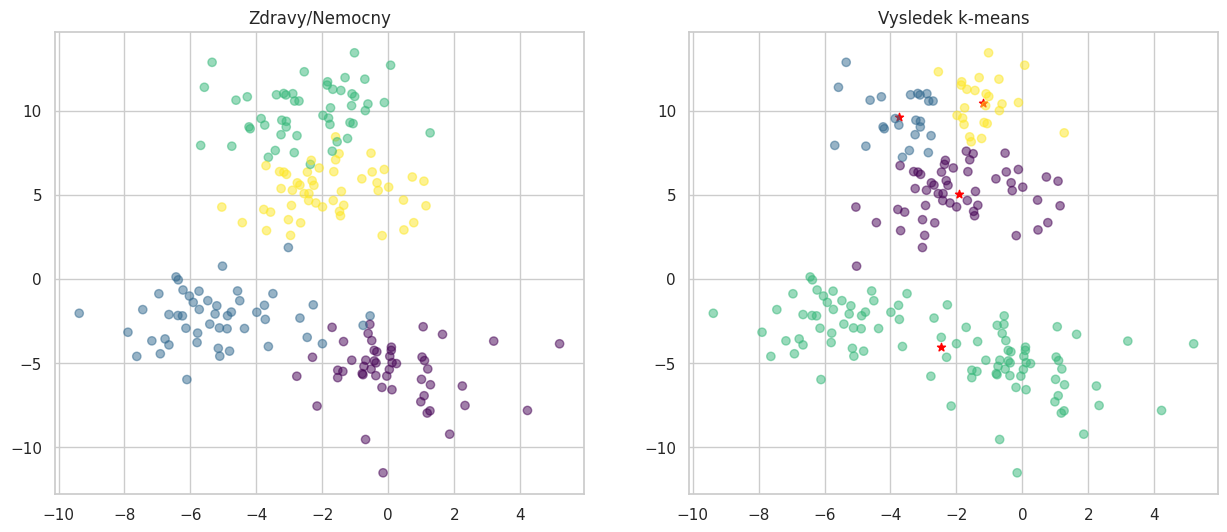

In [ ]:
 def compare_kmeans_gt(data_df, centroids, get_centroids, key):

     data = np.array(data_df)
     plt.figure(figsize=(15,6))
     plt.subplot(1, 2, 1)
     plt.scatter(data[:, 0], data[:, 1], alpha=0.5, c=key, cmap='viridis')
     plt.title("Zdravy/Nemocny")
     plt.subplot(1, 2, 2)
     plt.scatter(np.array(centroids)[:, 0], np.array(centroids)[:, 1], color='red', marker='*')
     plt.scatter(data[:, 0], data[:, 1], alpha=0.5, c=get_centroids, cmap='viridis')
     plt.title("Vysledek k-means")

key = data_fake[1]
compare_kmeans_gt(pd.DataFrame(data_fake[0]), centroids_new, get_centroids, key)


### Jak určit počet shluků k?

Elbow method (Metoda lokte): Sledujeme, jak rychle klesá inertia s rostoucím k. Křivka vždy může klesat, i když přidáváme zbytečné centroidy.

Silhouette score (−1 až 1) porovnává soudržnost vlastního shluku s oddělením od nejbližšího cizího shluku. Výsledek nemusí mít jednoznačné optimum.

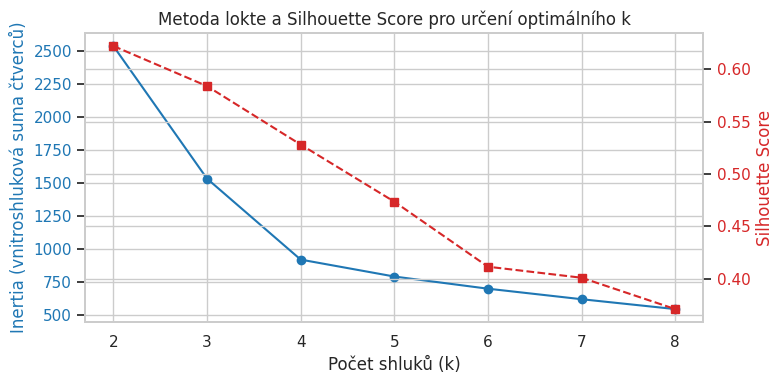

In [ ]:
inertia = []
silhouette_scores = []
k_range = range(2, 9)

X_fake = data_fake[0]

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_fake)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_fake, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))

color = 'tab:blue'
ax1.set_xlabel('Počet shluků (k)')
ax1.set_ylabel('Inertia (vnitroshluková suma čtverců)', color=color)
ax1.plot(k_range, inertia, marker='o', color=color, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_range, silhouette_scores, marker='s', color=color, linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Metoda lokte a Silhouette Score pro určení optimálního k')
fig.tight_layout()
plt.show()

### Změna měřítka bez změny informace

Pokud jeden příznak vynásobíme 100, geometrická vzdálenost se změní. Přitom jde pořád o stejná pozorování. Co se stane s k-means?

ARI oproti původním známým skupinám:
Bez standardizace: 0.21226617052911825
Po standardizaci: 0.5739630173053529


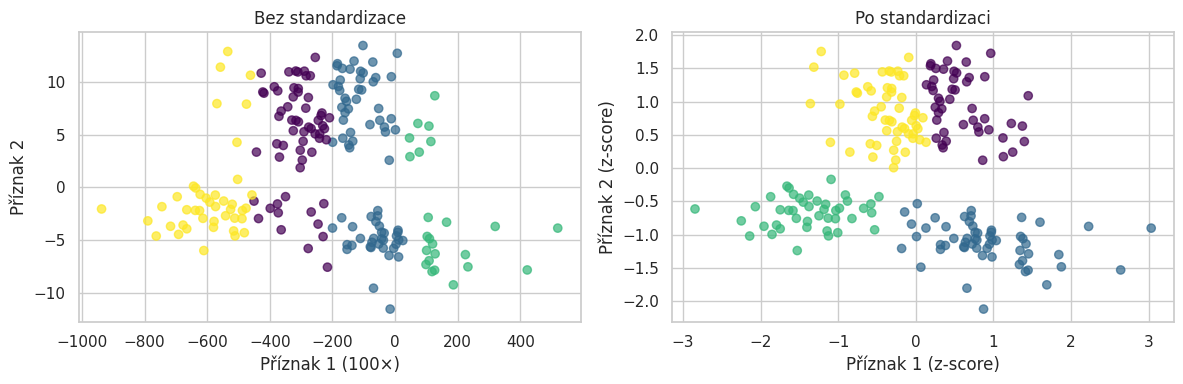

In [ ]:
X_scaled_wrong = data_fake[0].copy()
X_scaled_wrong[:, 0] *= 100

X_scaled_correct = StandardScaler().fit_transform(X_scaled_wrong)

wrong = KMeans(n_clusters=4, n_init=10).fit_predict(X_scaled_wrong)
fixed = KMeans(n_clusters=4, n_init=10).fit_predict(X_scaled_correct)

print("ARI oproti původním známým skupinám:")
print("Bez standardizace:", adjusted_rand_score(data_fake[1], wrong))
print("Po standardizaci:", adjusted_rand_score(data_fake[1], fixed))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_scaled_wrong[:, 0], X_scaled_wrong[:, 1],
                c=wrong, cmap="viridis", alpha=0.7)
axes[0].set_title("Bez standardizace")
axes[0].set_xlabel("Příznak 1 (100×)")
axes[0].set_ylabel("Příznak 2")

axes[1].scatter(X_scaled_correct[:, 0], X_scaled_correct[:, 1],
                c=fixed, cmap="viridis", alpha=0.7)
axes[1].set_title("Po standardizaci")
axes[1].set_xlabel("Příznak 1 (z-score)")
axes[1].set_ylabel("Příznak 2 (z-score)")

plt.tight_layout()
plt.show()

## K-means shlukování - reálná data

In [ ]:
root_dir = "/content/drive/MyDrive/"
base_dir = root_dir + "VMM/cviceni_08/"
data_path = base_dir
source_file = Path(data_path) / "cviceni4_data_orig.json"

from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load data from file
import scipy.stats as stats

data_real = pd.read_json(f'{data_path}cviceni4_data_orig.json')

# Standardizace všech příznaků kromě isAFIB
data_stand = data_real.drop(columns=['isAFIB']).apply(stats.zscore)

# Přidání původního sloupce isAFIB
data_stand['isAFIB'] = data_real['isAFIB']

print(data_stand.head())

        Age       Sex           BMI       Job  meanPdurat    meanRR  \
0 -1.273501  0.733799 -4.574229e-01 -1.110632   -1.139562  0.852839   
1 -1.339259  0.733799 -1.515127e+00 -1.110632    0.808918  0.441219   
2 -1.141987  0.733799  7.136071e-01  0.123404    1.076578  0.423493   
3  1.225279  0.733799 -3.145750e-12 -1.110632    0.847479  0.244445   
4 -0.221383  0.733799 -3.145750e-12  0.123404    0.951821  0.227765   

   meadianRR     stdRR     rmssd  varcoeff  isAFIB  
0   0.843994 -0.939561 -0.958621 -1.012461       0  
1   0.407279 -1.050869 -0.967784 -1.072318       0  
2   0.384090 -1.017815 -0.949223 -1.045922       0  
3   0.183124  1.630399  1.637197  1.129562       1  
4   0.221771 -1.048498 -0.944744 -1.060081       0  


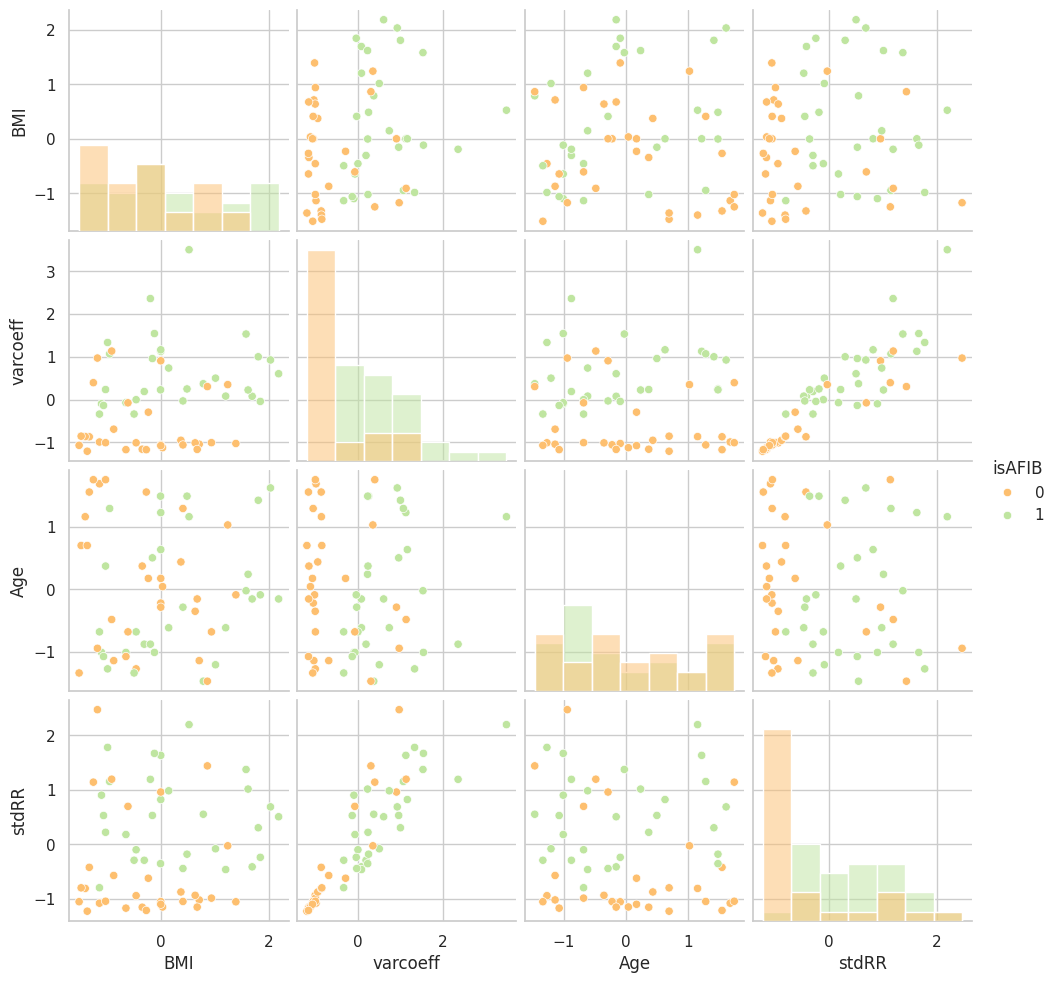

In [ ]:
# Diagnostický štítek pouze pro barevné odlišení, nikoli pro shlukování.
# Výběr menšího počtu příznaků kvůli přehlednosti grafu.
plot_cols = [c for c in ["BMI", "varcoeff", "Age", "stdRR"] if c in data_stand.columns]
sns.pairplot(data_stand[plot_cols + ["isAFIB"]], hue="isAFIB", palette="Spectral", diag_kind="hist")
plt.show()

Odpovězte:
1. Do kolika shluků bude vhodné tato data rozdělit a proč? Je to jednoznačné?
  - Rozhodně to není jednoznačné. Shluková analýza je nepodmíněná (unsupervised) a nezná diagnózu. Data tvoří v prostoru převážně jedno spojité mračno s plynulým přechodem a odlehlými hodnotami spíše než jasně oddělené kompaktní kuličky. Metoda lokte či Silhouette skóre mohou ukazovat jiné optimum (např. $k=3$ kvůli odlehlým/těžším pacientům).
2. Lze očekávat, že nalezené shluky budou odpovídat diagnóze AFIB?
  - Nelze to plně očekávat.
  - Skupiny se v prostoru příznaků znatelně překrývají (pacienti s AFIB nemají ostře oddělené hranice od zdravých). $K$-means navíc předpokládá kulové, stejně velké a oddělené shluky. Místo čistého rozdělení na nemocné/zdravé tak algoritmus pravděpodobně rozdělí data podle celkového rozptylu nebo odlehlosti pacientů.
3. Které dva příznaky by se hodily pro shlukování a proč?
  - varcoeff (variační koeficient) a stdRR (směrodatná odchylka RR intervalů)
  - Důvod: AFIB (fibrilace síní) je charakteristická nepravidelným srdečním rytmem. Variabilita RR intervalů (stdRR) a její poměr k průměru (varcoeff) přímo kvantifikují tuto nepravidelnost. V grafech mají tyto dva příznaky největší schopnost odlišit pacienty s AFIB od kontrolní skupiny oproti obecným demografickým parametrům jako Age nebo BMI.

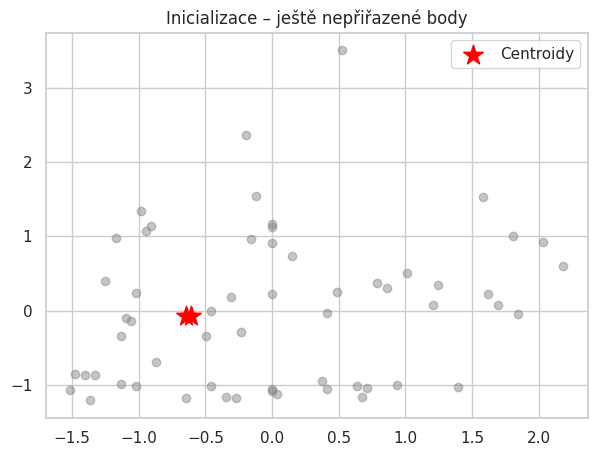

Iterace 1: největší posun centroidu = 1.10358


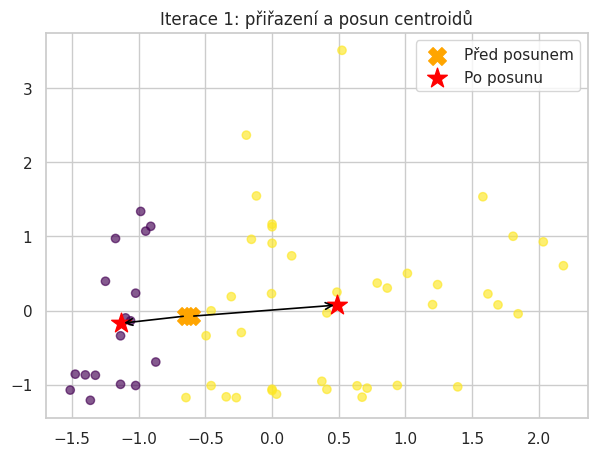

Iterace 2: největší posun centroidu = 0.24626


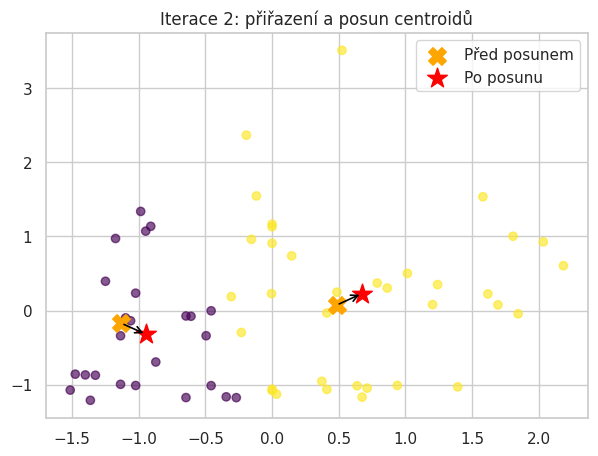

Iterace 3: největší posun centroidu = 0.19862


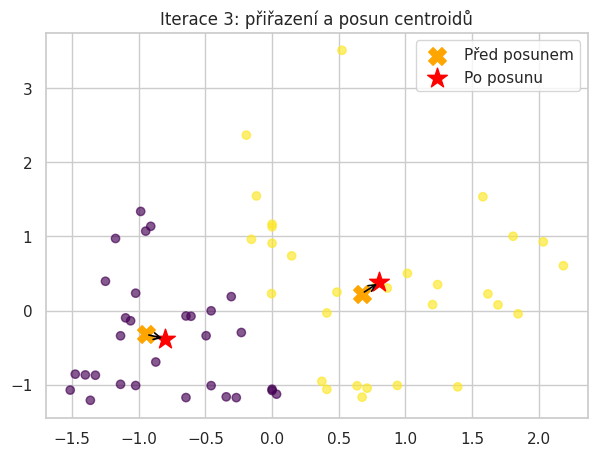

Iterace 4: největší posun centroidu = 0.10345


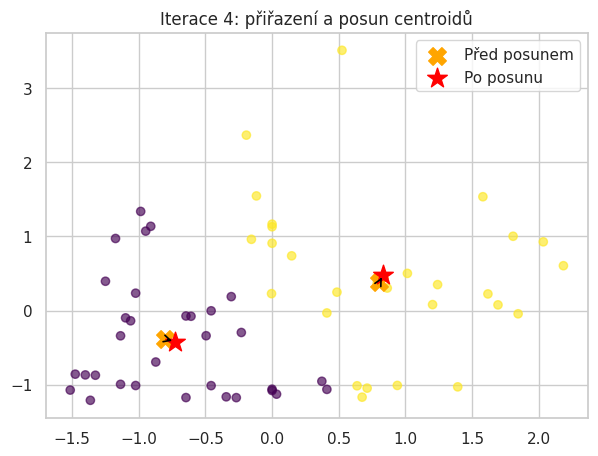

Iterace 5: největší posun centroidu = 0.12158


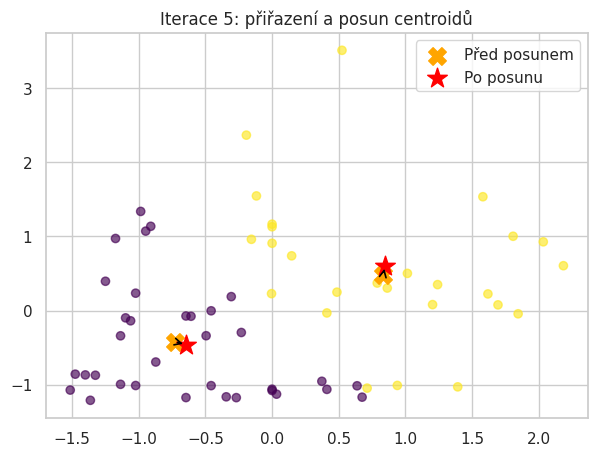

Iterace 6: největší posun centroidu = 0.06606


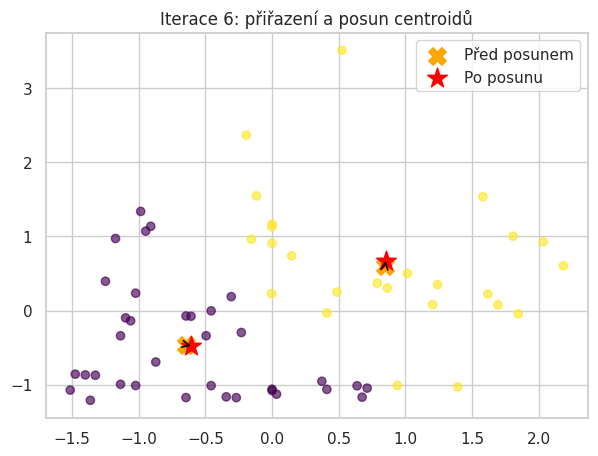

Iterace 7: největší posun centroidu = 0.09782


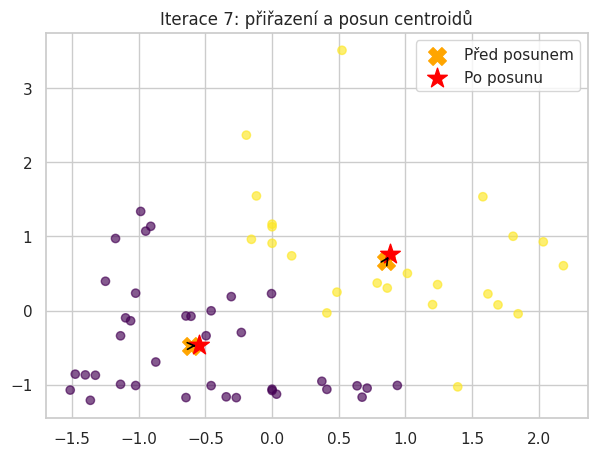

Iterace 8: největší posun centroidu = 0.00000


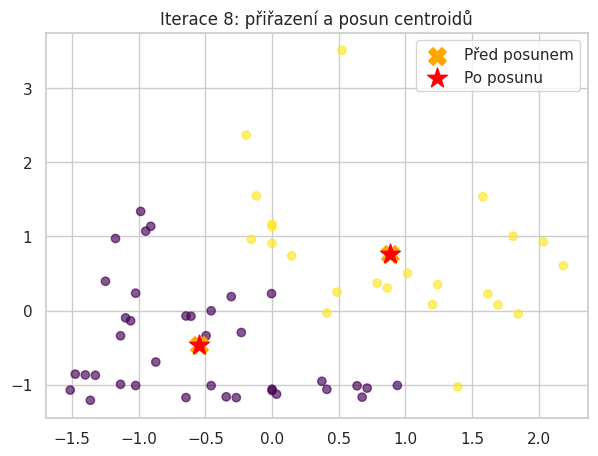

Konvergence: centroidy se už téměř nepohybují.


In [ ]:
#K-means clustering on all original data
data_select = data_stand[["BMI", "varcoeff"]]

centroids_new_real, get_centroids_real = run_kmeans(data_select.to_numpy(), 2)

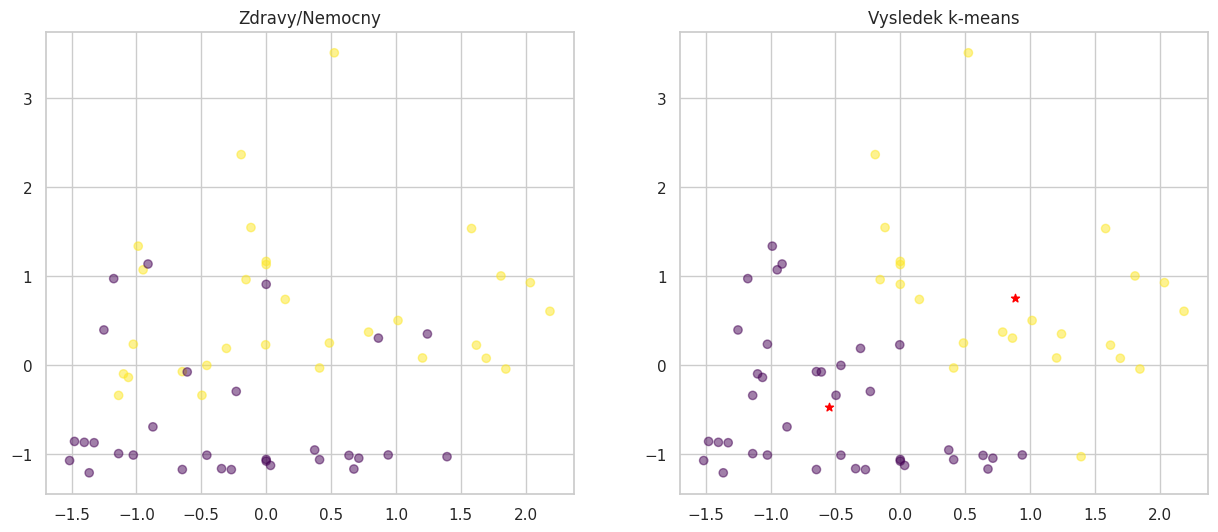

In [ ]:
compare_kmeans_gt(data_select, centroids_new_real, get_centroids_real, data_real["isAFIB"])

In [ ]:
y = data_stand["isAFIB"]

print("ARI:", adjusted_rand_score(y, get_centroids_real))

print("\nPočty pacientů podle diagnózy a nalezeného shluku:")
print(pd.crosstab(y, get_centroids_real,
                  rownames=["isAFIB"],
                  colnames=["Shluk"]))

ARI: 0.2377844552048843

Počty pacientů podle diagnózy a nalezeného shluku:
Shluk    0   1
isAFIB        
0       26   4
1       11  19


## Kolik shluků je vhodných u reálných dat?

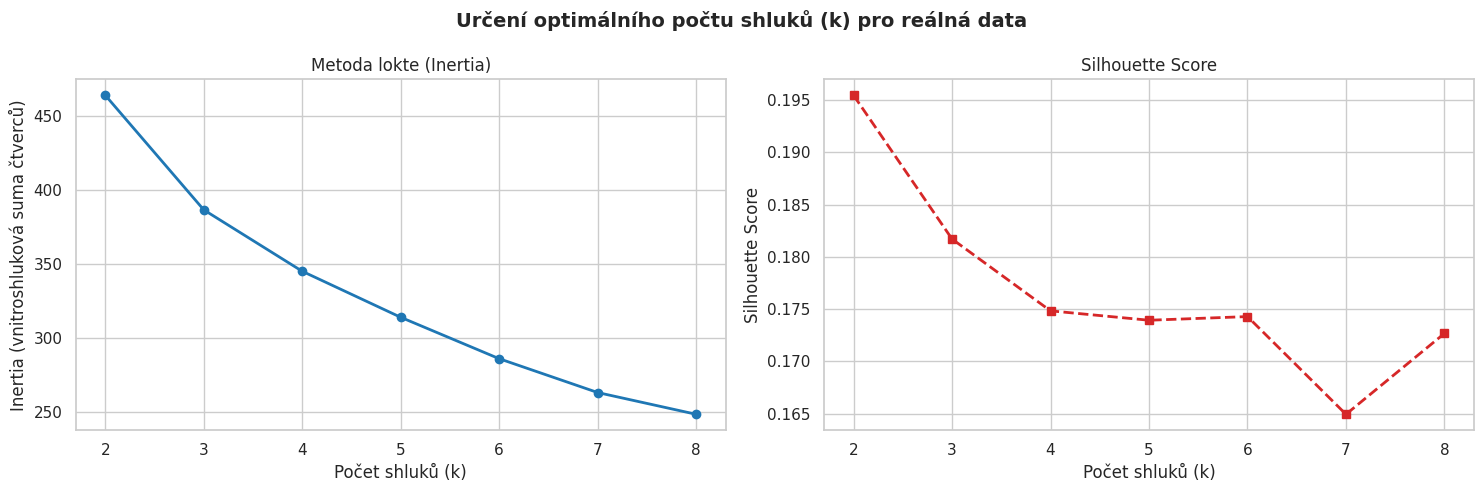

In [ ]:
inertia_real = []
silhouette_real = []
k_range = range(2, 9)

# Pro analýzu použijeme všechna reálná standardizovaná data kromě cílového sloupce isAFIB
X_real = data_stand.drop(columns=['isAFIB'])

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_real)
    inertia_real.append(kmeans.inertia_)
    silhouette_real.append(silhouette_score(X_real, labels))

# Vykreslení 2 grafů vedle sebe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Levý graf: Metoda lokte (Inertia)
ax1.plot(k_range, inertia_real, marker='o', color='tab:blue', linewidth=2)
ax1.set_xlabel('Počet shluků (k)')
ax1.set_ylabel('Inertia (vnitroshluková suma čtverců)')
ax1.set_title('Metoda lokte (Inertia)')
ax1.grid(True)

# Pravý graf: Silhouette Score
ax2.plot(k_range, silhouette_real, marker='s', color='tab:red', linestyle='--', linewidth=2)
ax2.set_xlabel('Počet shluků (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score')
ax2.grid(True)

plt.suptitle('Určení optimálního počtu shluků (k) pro reálná data', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Využití PCA pro shlukování

In [ ]:
from sklearn.decomposition import PCA

# Odstranění diagnostického sloupce
data_for_pca = data_stand.drop(columns=["isAFIB"])

# PCA ze všech standardizovaných vstupních příznaků
pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(data_for_pca)

print("Rozptyl vysvětlený PC1 a PC2:", np.round(pca.explained_variance_ratio_, 3))
print("Celkem vysvětlený rozptyl:", round(sum(pca.explained_variance_ratio_), 3))

Rozptyl vysvětlený PC1 a PC2: [0.315 0.239]
Celkem vysvětlený rozptyl: 0.555


,Age,Sex,BMI,Job,meanPdurat,meanRR,meadianRR,stdRR,rmssd,varcoeff,isAFIB,PC1,PC2
0,-1.273501,0.733799,-4.574229e-01,-1.110632,-1.139562,0.852839,0.843994,-0.939561,-0.958621,-1.012461,0,-1.681429,0.700298
1,-1.339259,0.733799,-1.515127e+00,-1.110632,0.808918,0.441219,0.407279,-1.050869,-0.967784,-1.072318,0,-2.376720,0.624861
2,-1.141987,0.733799,7.136071e-01,0.123404,1.076578,0.423493,0.384090,-1.017815,-0.949223,-1.045922,0,-1.838568,-0.223867
3,1.225279,0.733799,-3.145750e-12,-1.110632,0.847479,0.244445,0.183124,1.630399,1.637197,1.129562,1,1.496500,1.768043
4,-0.221383,0.733799,-3.145750e-12,0.123404,0.951821,0.227765,0.221771,-1.048498,-0.944744,-1.060081,0,-1.866847,-0.442305


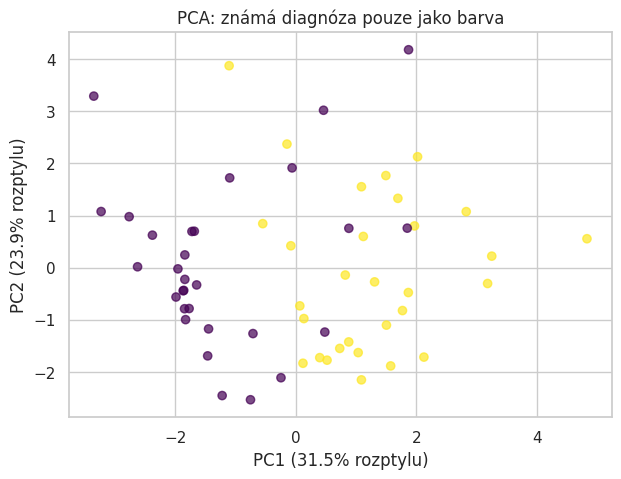

In [ ]:
new_data = pd.DataFrame(pca_coordinates, columns=["PC1", "PC2"], index=data_stand.index)
data = data_stand.join(new_data)
display(data.head())
plt.figure(figsize=(7, 5))
plt.scatter(data["PC1"], data["PC2"], c=pd.factorize(data["isAFIB"])[0], cmap="viridis", alpha=.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} rozptylu)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} rozptylu)")
plt.title("PCA: známá diagnóza pouze jako barva")
plt.show()

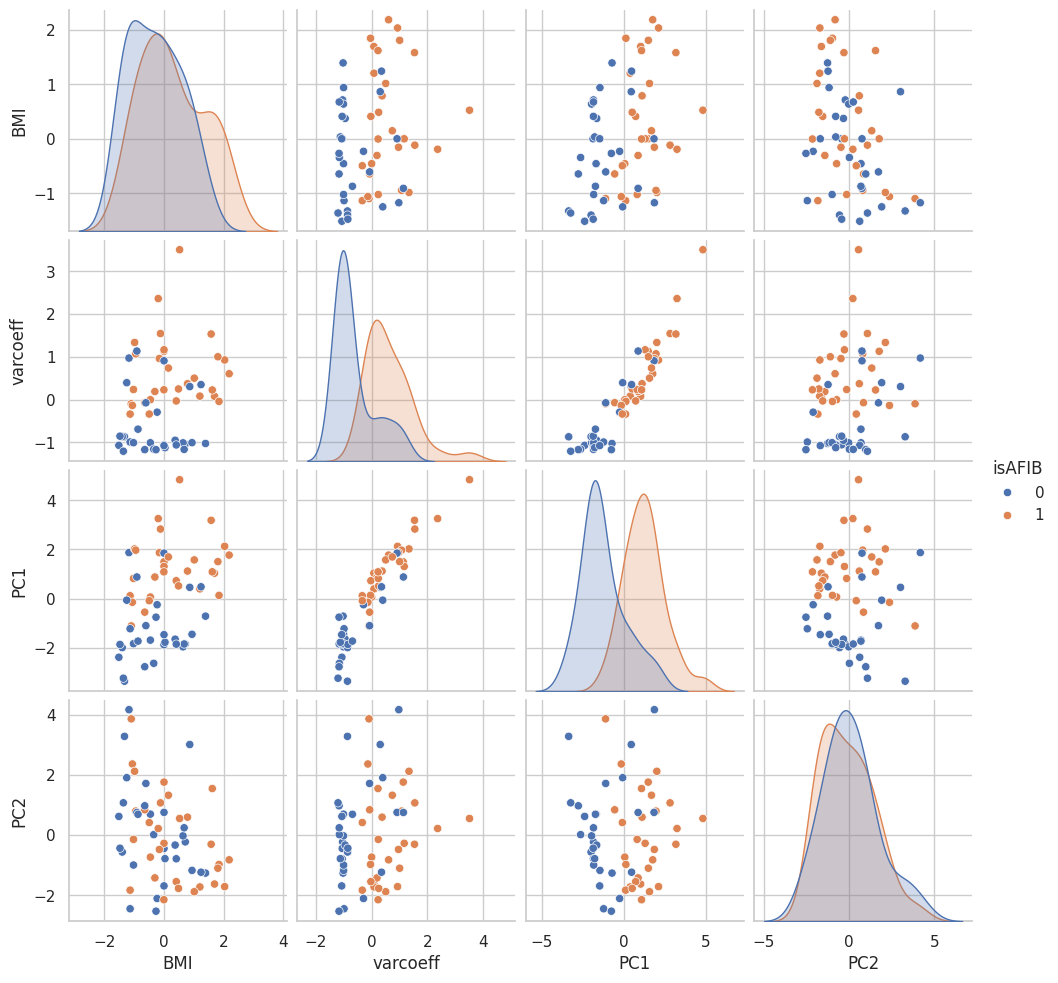

In [ ]:
sns.pairplot(data[["BMI", "varcoeff", "PC1", "PC2", "isAFIB"]], hue="isAFIB")

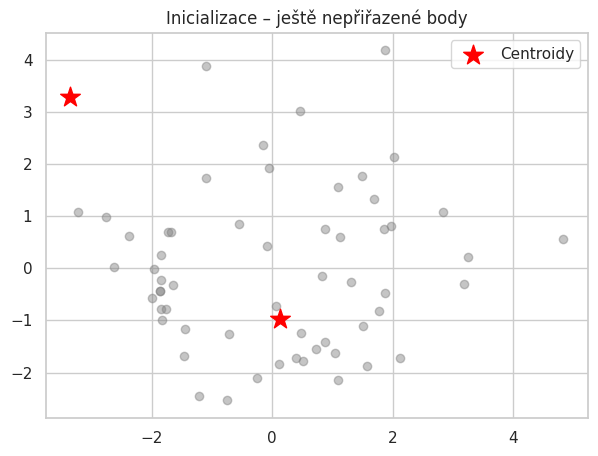

Iterace 1: největší posun centroidu = 2.25319


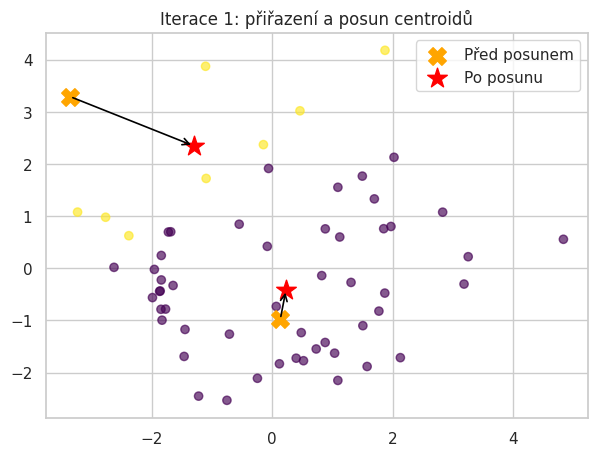

Iterace 2: největší posun centroidu = 0.59248


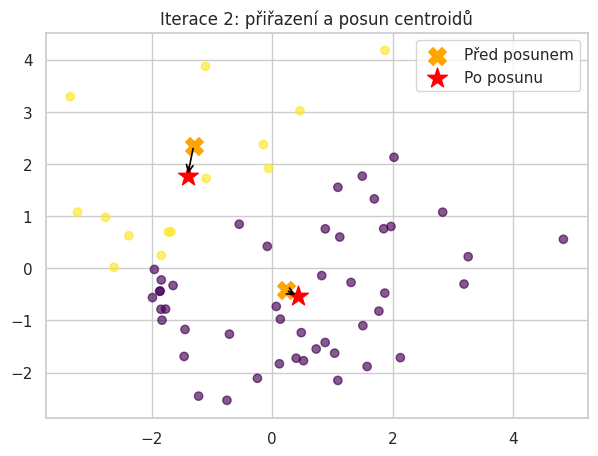

Iterace 3: největší posun centroidu = 0.57751


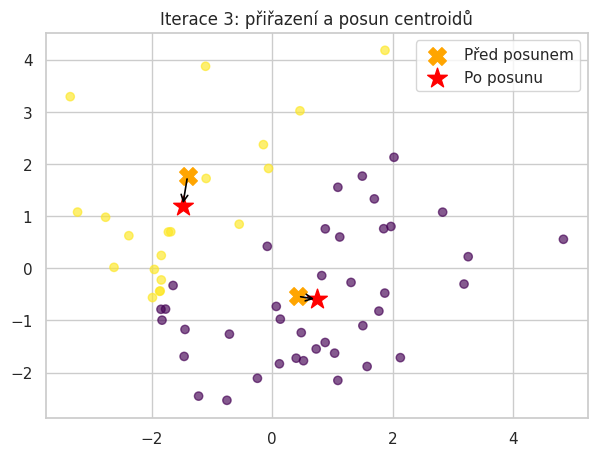

Iterace 4: největší posun centroidu = 0.32321


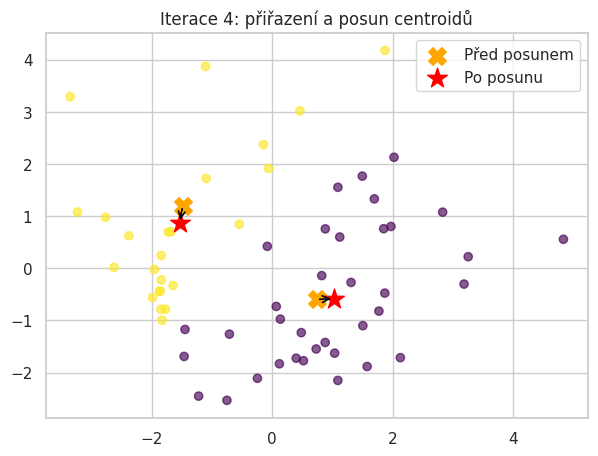

Iterace 5: největší posun centroidu = 0.17756


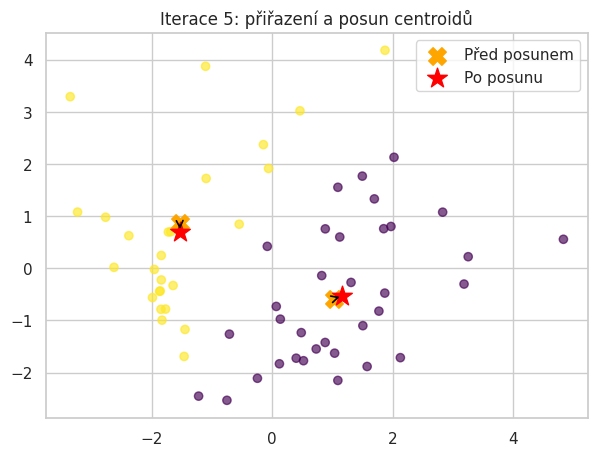

Iterace 6: největší posun centroidu = 0.16299


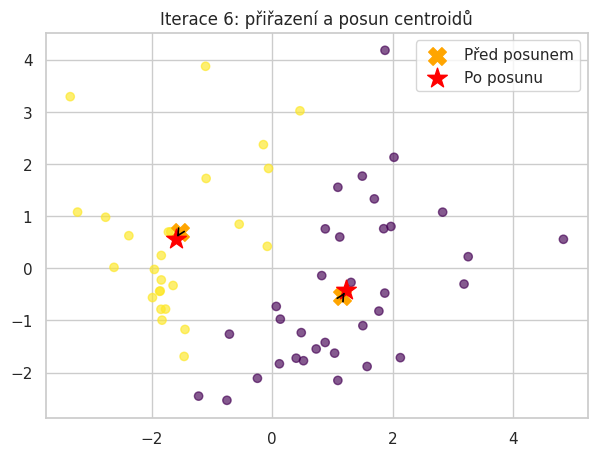

Iterace 7: největší posun centroidu = 0.17808


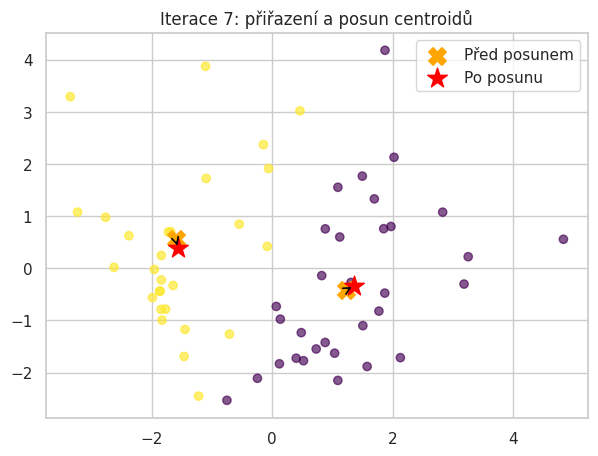

Iterace 8: největší posun centroidu = 0.10423


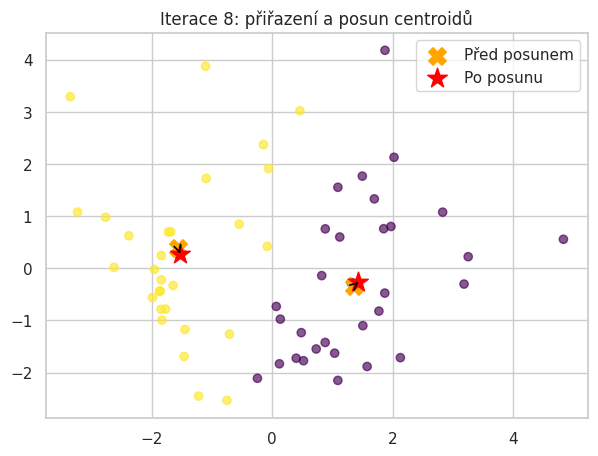

Iterace 9: největší posun centroidu = 0.00000


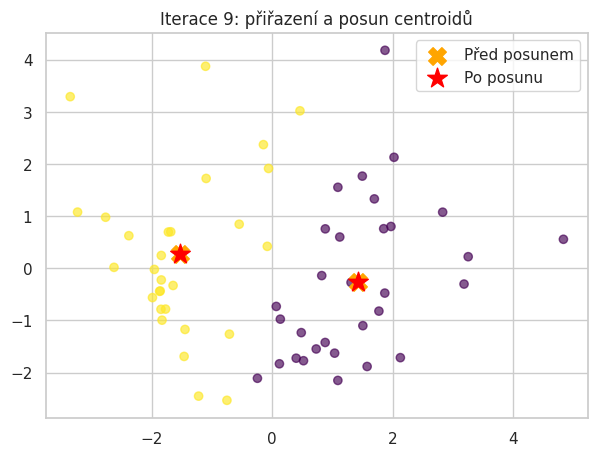

Konvergence: centroidy se už téměř nepohybují.
ARI po PCA: 0.481216834926534


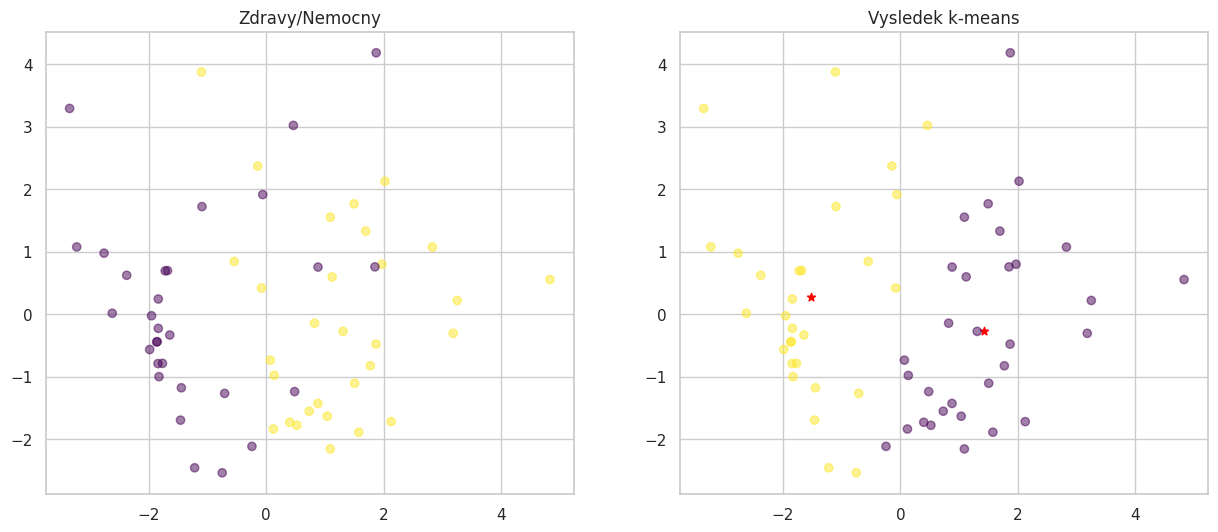

In [ ]:
# Shlukování k-means na komponentách PC1 a PC2
data_pca = data[["PC1", "PC2"]]

centroids_new_pca, get_centroids_pca = run_kmeans(data_pca.to_numpy(), 2)
compare_kmeans_gt(data_pca, centroids_new_pca, get_centroids_pca, y)

labels_pca = get_centroids_pca
print("ARI po PCA:", adjusted_rand_score(y, labels_pca))

ARI před PCA (BMI, varcoeff): 0.238
ARI po PCA (PC1, PC2):       0.530


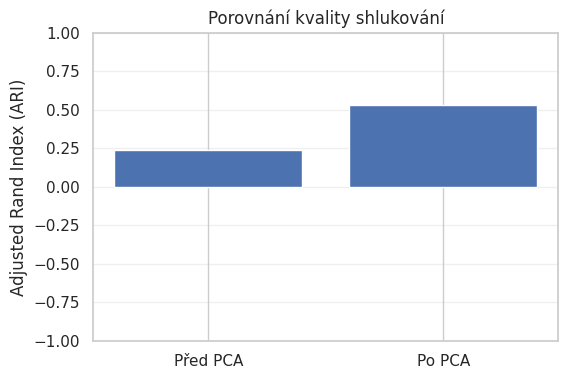

In [ ]:
# Porovnání ARI před PCA a po PCA
ari_before = adjusted_rand_score(y, get_centroids_real)
ari_after = adjusted_rand_score(y, labels_pca)

print(f"ARI před PCA (BMI, varcoeff): {ari_before:.3f}")
print(f"ARI po PCA (PC1, PC2):       {ari_after:.3f}")

# Grafické porovnání
plt.figure(figsize=(6, 4))
plt.bar(["Před PCA", "Po PCA"], [ari_before, ari_after])
plt.ylabel("Adjusted Rand Index (ARI)")
plt.title("Porovnání kvality shlukování")
plt.ylim(-1, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

## Shlukování jako nástroj pro detekci odlehlých hodnot
* Jak budou odlehlé hodnoty ovlivňovat výsledky shlukování?
  - Vychýlení centroidů: $k$-means počítá novou pozici centroidu jako aritmetický průměr všech přiřazených bodů. Průměr je extrémně citlivý na odlehlé hodnoty, takže i jediný výrazný outlier může přitáhnout centroid daleko od hustého jádra shluku.
  - Vznik izolovaných/triviálních shluků: Pokud je outlier dostatečně vzdálený, algoritmus mu může přiřadit samostatný shluk (shluk o 1 až 2 prvcích), čímž „vyplýtvá“ jeden centroid na úkor zbytku dat.
  - Zkreslení eukleidovské metriky a hranic: Eukleidovská vzdálenost roste kvadraticky s odchylkou, což deformuje hranice mezi přirozenými shluky a zhoršuje soudržnost (inertia).
* Jaký by mohl být postup pro detekci odlehlých hodnot?
  1. Výpočet vzdálenosti k centroidu: U každého bodu spočítat vzdálenost od jeho přiřazeného středu.
  2. Nastavení prahu: Body ležící nejdále (např. nad 95. percentilem nebo $3\sigma$) označit jako odlehlé.
  3. Malé shluky: Zkontrolovat shluky s minimem prvků (často jde o skupinu outlierů).
  4. Přeclusterování: Odlehlé body odstranit a $k$-means pustit znovu na očištěných datech.

In [ ]:
# Příprava proměnných (pokud ještě nejsou definovány)
rng = np.random.default_rng(RANDOM_STATE)
X = data_stand[["BMI", "varcoeff"]].copy()

# Vytvoříme 3 umělé odlehlé hodnoty v již standardizovaných příznacích.
# Originální tabulku neměníme.
data_outliers = X.copy()
outlier_idx = rng.choice(len(data_outliers), size=min(3, len(data_outliers)), replace=False)
data_outliers.loc[outlier_idx, "BMI"] += 6.0  # šest jednotek z-skóre
# varcoeff posuneme také, aby odlehlé body byly dobře viditelné v 2D.
data_outliers.loc[outlier_idx, "varcoeff"] += 6.0
print("Indexy vložených umělých odlehlých hodnot:", outlier_idx)

Indexy vložených umělých odlehlých hodnot: [45 46 42]


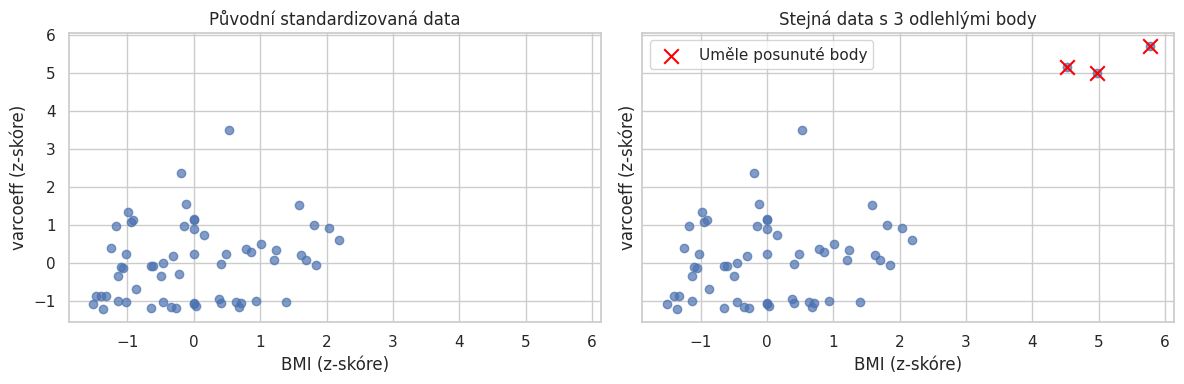

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
axes[0].scatter(X["BMI"], X["varcoeff"], alpha=.7)
axes[0].set_title("Původní standardizovaná data")
axes[1].scatter(data_outliers["BMI"], data_outliers["varcoeff"], alpha=.7)
axes[1].scatter(data_outliers.loc[outlier_idx, "BMI"], data_outliers.loc[outlier_idx, "varcoeff"],
                marker="x", s=110, color="red", label="Uměle posunuté body")
axes[1].set_title("Stejná data s 3 odlehlými body");axes[1].legend()
for ax in axes:
    ax.set_xlabel("BMI (z-skóre)");ax.set_ylabel("varcoeff (z-skóre)")
plt.tight_layout();plt.show()

Iterace 1: největší posun centroidu = 1.07962
Iterace 2: největší posun centroidu = 0.12158
Iterace 3: největší posun centroidu = 0.06606
Iterace 4: největší posun centroidu = 0.09782
Iterace 5: největší posun centroidu = 0.00000
Konvergence: centroidy se už téměř nepohybují.
Iterace 1: největší posun centroidu = 2.06205
Iterace 2: největší posun centroidu = 0.40693
Iterace 3: největší posun centroidu = 0.23665
Iterace 4: největší posun centroidu = 0.37648
Iterace 5: největší posun centroidu = 0.38571
Iterace 6: největší posun centroidu = 0.88718
Iterace 7: největší posun centroidu = 0.35211
Iterace 8: největší posun centroidu = 0.77242
Iterace 9: největší posun centroidu = 1.39746
Iterace 10: největší posun centroidu = 1.22393
Iterace 11: největší posun centroidu = 0.00000
Konvergence: centroidy se už téměř nepohybují.


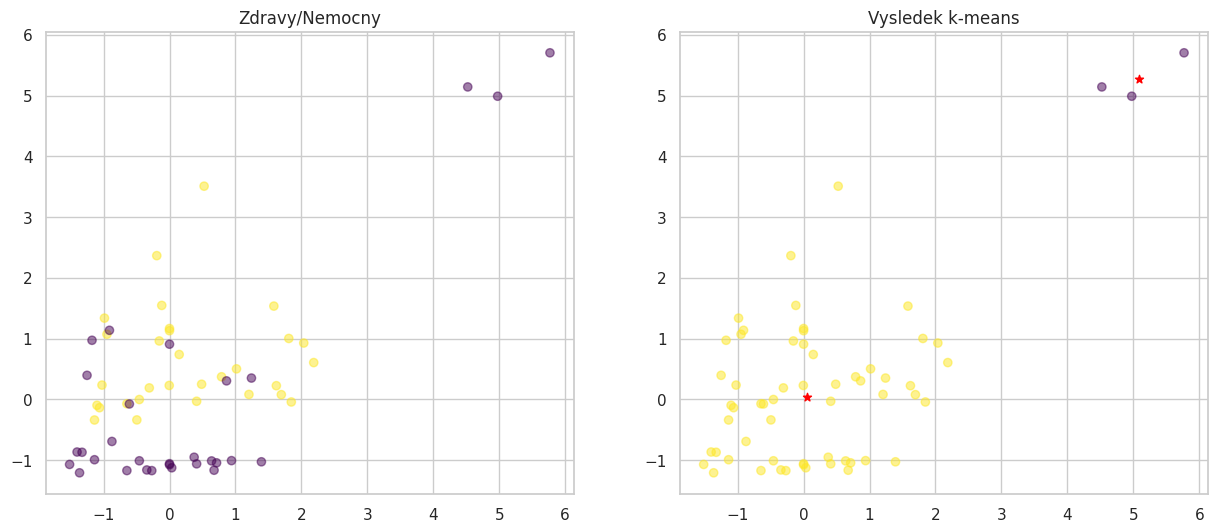

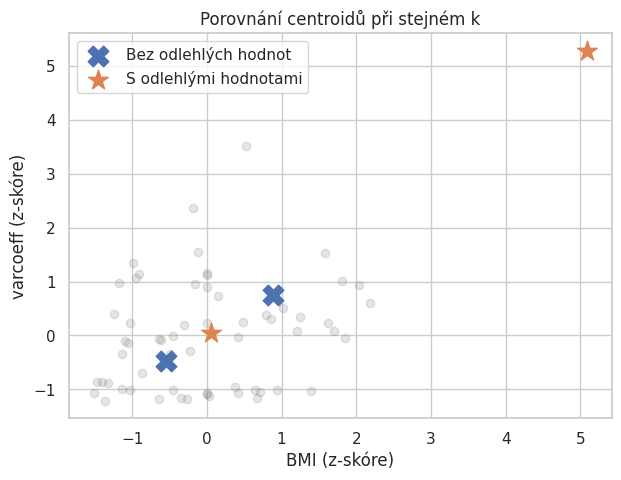

In [ ]:
key_r = data_stand["isAFIB"]

centroids_base, labels_base = run_kmeans(X.values, 2, 15, show_steps=False)
centroids_new_out, get_centroids_out = run_kmeans(data_outliers.values, 2, 15, show_steps=False)

compare_kmeans_gt(data_outliers, centroids_new_out, get_centroids_out, key_r)

# Centroidy mohou po přidání odlehlých hodnot změnit polohu či rozdělení bodů.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X.iloc[:, 0], X.iloc[:, 1], alpha=.2, color="gray")
ax.scatter(centroids_base[:, 0], centroids_base[:, 1], s=220, marker="X", label="Bez odlehlých hodnot")
ax.scatter(centroids_new_out[:, 0], centroids_new_out[:, 1], s=220, marker="*", label="S odlehlými hodnotami")
ax.set(xlabel="BMI (z-skóre)", ylabel="varcoeff (z-skóre)", title="Porovnání centroidů při stejném k")
ax.legend()
plt.show()

## Kdy k-means selhává? Dva půlměsíce

Představte si dva jasně odlišné srpkovité shluky. K-means vytváří oblasti kolem centroidů, což nemusí odpovídat nelineárnímu tvaru skutečných skupin. Připomeňte si data z Kernel PCA.

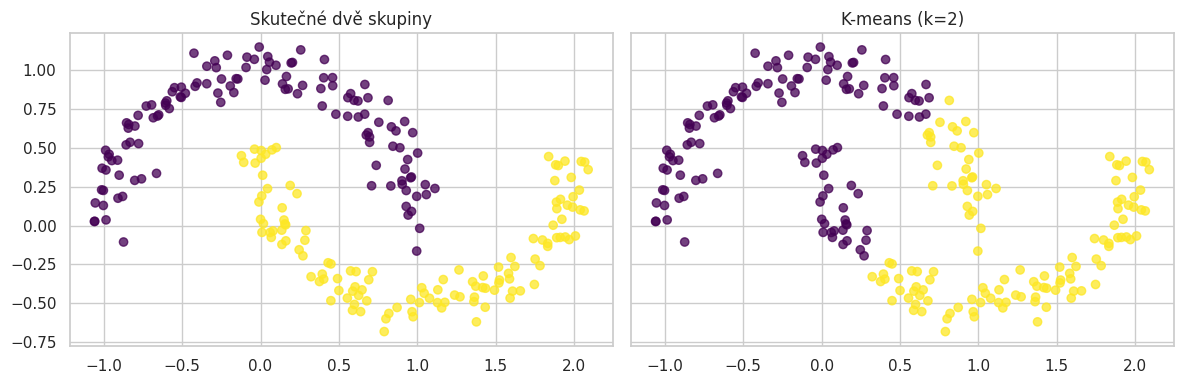

ARI k-means pro půlměsíce: 0.235


In [ ]:
X_moons, y_moons = make_moons(n_samples=250, noise=.08, random_state=RANDOM_STATE)
lab_moons = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_moons)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, labs, title in zip(axes, [y_moons, lab_moons], ["Skutečné dvě skupiny", "K-means (k=2)"]):
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labs, cmap="viridis", alpha=.75)
    ax.set_title(title)
plt.tight_layout();plt.show()
print("ARI k-means pro půlměsíce:", round(adjusted_rand_score(y_moons, lab_moons), 3))
